In [1]:
# import libraries
import numpy as np
import pandas as pd
from pathlib import Path

In [ ]:
# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# 
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
df = pokemon_all.merge(sets_df, on="set_slug", how="left")


In [3]:
# cleaning
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10



for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [ ]:
pokemon_all.info()

pokemon_all["variant"].unique()
pokemon_all["grade"].unique()

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chartgazing as cg

VALUE, GROUP, NAME = "price", "decade", "set_name"

unit_prefix = "$"
marker_size = 4.5


def swarm(x, diameter):
    """y offsets (same units as x) so dots of the given diameter don't overlap. Greedy, centre-out."""
    order = np.argsort(x)
    ys = np.zeros(len(x))
    placed_x, placed_y = [], []
    for i in order:
        xi = x[i]
        near = [(xj, yj) for xj, yj in zip(placed_x, placed_y) if abs(xj - xi) < diameter]
        candidates = [0.0]
        for xj, yj in near:
            dy = np.sqrt(diameter ** 2 - (xi - xj) ** 2)
            candidates += [yj + dy, yj - dy]
        for c in sorted(candidates, key=abs):
            if all((xi - xj) ** 2 + (c - yj) ** 2 >= diameter ** 2 - 1e-9 for xj, yj in near):
                ys[i] = c
                break
        placed_x.append(xi)
        placed_y.append(ys[i])
    return ys


def set_price_comparison(df, grade="Ungraded", variant="Standard", stat="median"):
    latest = df[
        (df["variant"] == variant) 
        & (df["grade"] == grade)
        & (df["date"] == df["date"].max())
        ]

    set_prices = (
        latest.groupby("set_name", observed=True)
        .agg(price=("price", stat), decade=("decade", "first"))
        .dropna(subset=["decade", "price"])
        .reset_index()
    )
    set_prices["decade"] = set_prices["decade"].astype(int).astype(str) + "s"

    return set_prices.sort_values('price', ascending=False)

def decade_beeswarm(df, title, subtitle, path, highlight=(), note="", source="", 
                    x_range=(0.15,200), x_ticks=(0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200)):

    order = sorted(df[GROUP].unique(), reverse=True)   # 1990s on top

    fig, ax = cg.chart(title, subtitle, note=note, source=source, grid="x")

    ax.set_xscale("log")
    ax.set_xlim(*x_range)
    ax.set_xticks(x_ticks, [f"{unit_prefix}{t:g}" for t in x_ticks])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_yticks(range(len(order)), order)

    # the swarm is laid out in points, so fit the layout first to know the final axes size
    # on a log axis, distance is measured in log10 units
    cg.fit(fig)
    bbox = ax.get_window_extent()
    pt = 72 / fig.dpi
    x_per_pt = np.diff(np.log10(ax.get_xlim()))[0] / (bbox.width * pt)
    y_per_pt = np.diff(ax.get_ylim())[0] / (bbox.height * pt)

    for yi, group_name in enumerate(order):
        group = df[df[GROUP] == group_name]
        offsets = swarm(np.log10(group[VALUE].to_numpy()) / x_per_pt, marker_size * 1.05) * y_per_pt
        is_hl = group[NAME].isin(highlight).to_numpy()

        ax.scatter(group[VALUE][~is_hl], yi + offsets[~is_hl], s=marker_size ** 2,
                color=cg.SECONDARY, alpha=0.75, linewidth=0, clip_on=False)
        ax.scatter(group[VALUE][is_hl], yi + offsets[is_hl], s=(marker_size * 1.3) ** 2,
                color=cg.PRIMARY, edgecolor=cg.BACKGROUND, linewidth=0.6, zorder=3, clip_on=False)

        for name, xv, yo in zip(group[NAME][is_hl], group[VALUE][is_hl], offsets[is_hl]):
            ax.annotate(name, xy=(xv, yi + yo), xytext=(0, 6), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7.5, fontweight="bold", color=cg.TEXT)

    cg.save(fig, path)
    plt.show()



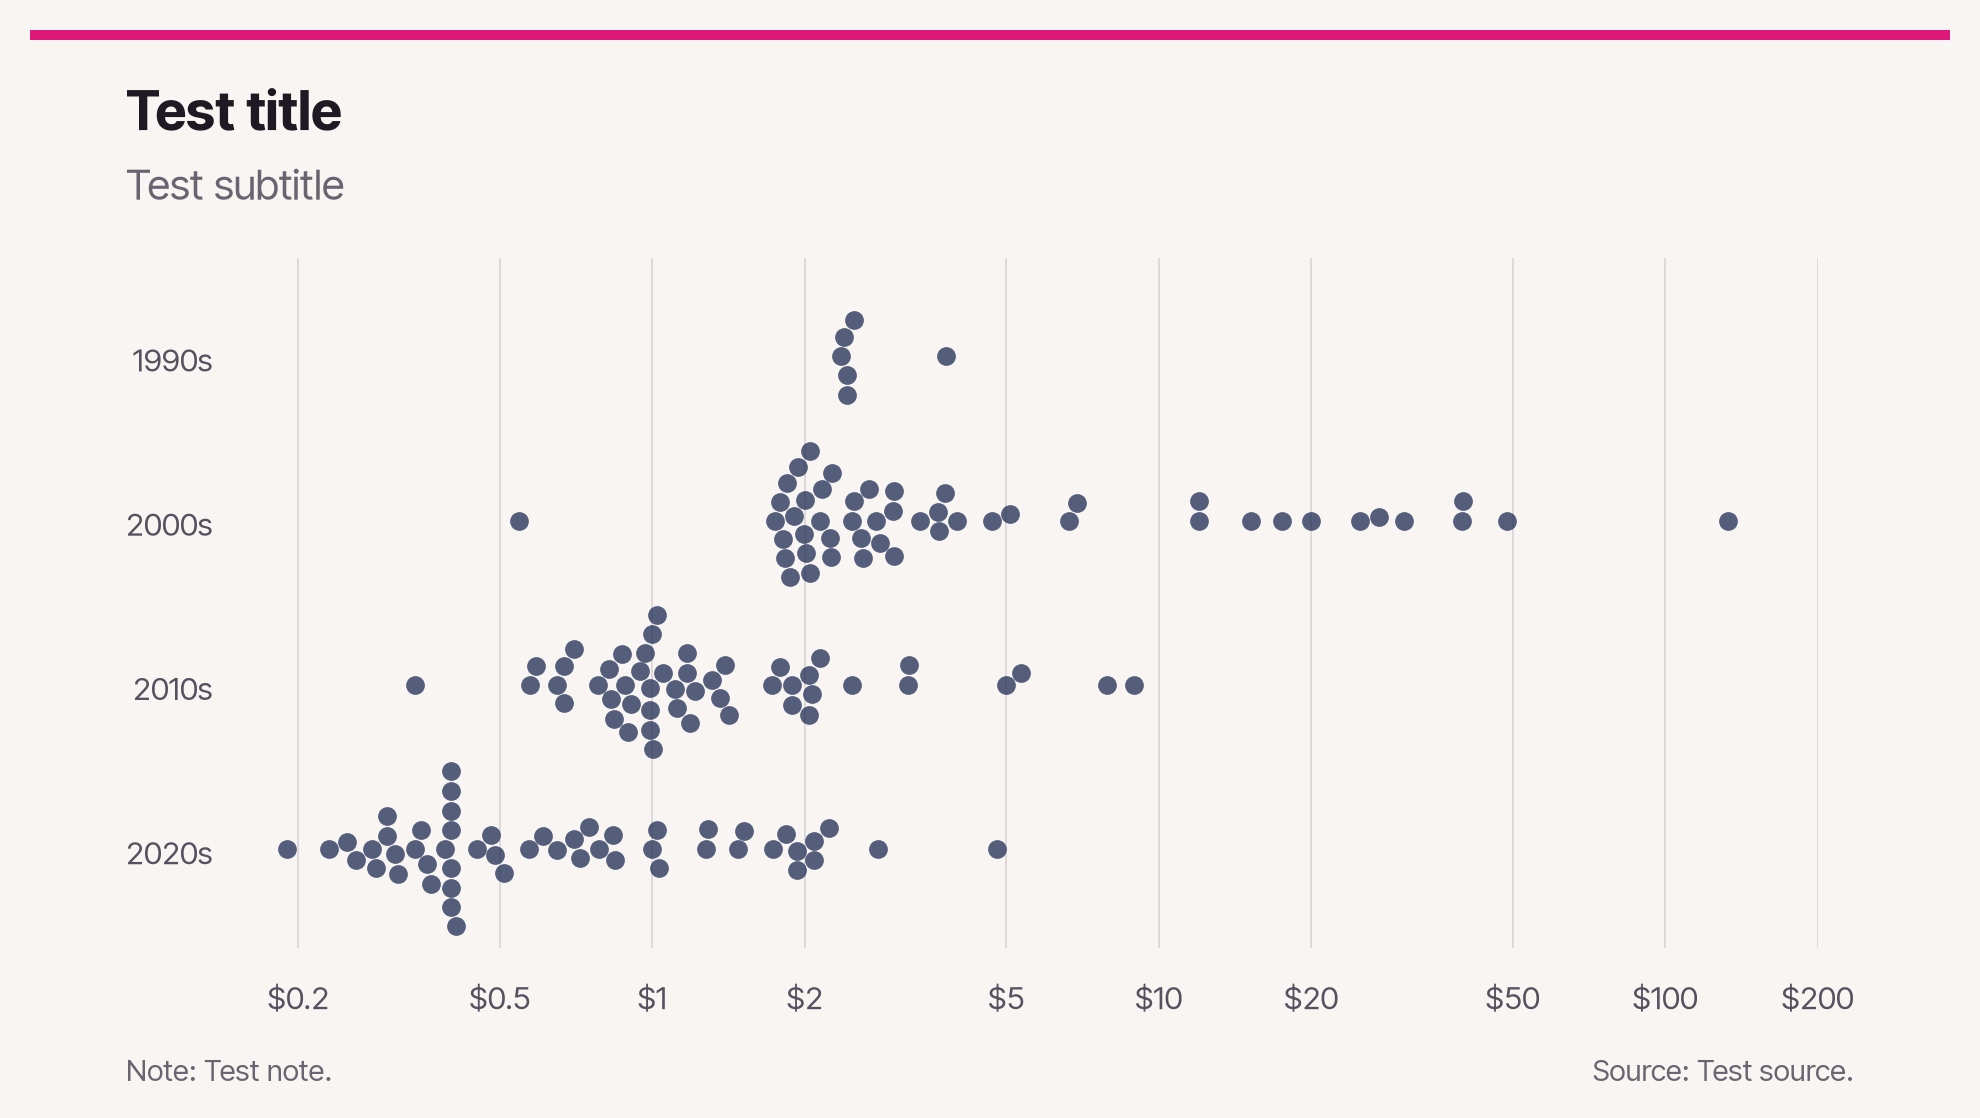

In [12]:
set_prices = set_price_comparison(pokemon_all)


title = "Test title"
subtitle = "Test subtitle"
path = "images/beeswarm_test.png"
source = "Source: Test source."
note = "Note: Test note."

decade_beeswarm(set_prices, title, subtitle, path, highlight=(), note=note, source=source, 
                    x_range=(0.15,200), x_ticks=(0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200))